In [44]:
import pandas as pd 
import numpy as np
import datetime         #Shows in my time zone COL.

BBB-880 AIR2
8B51422F

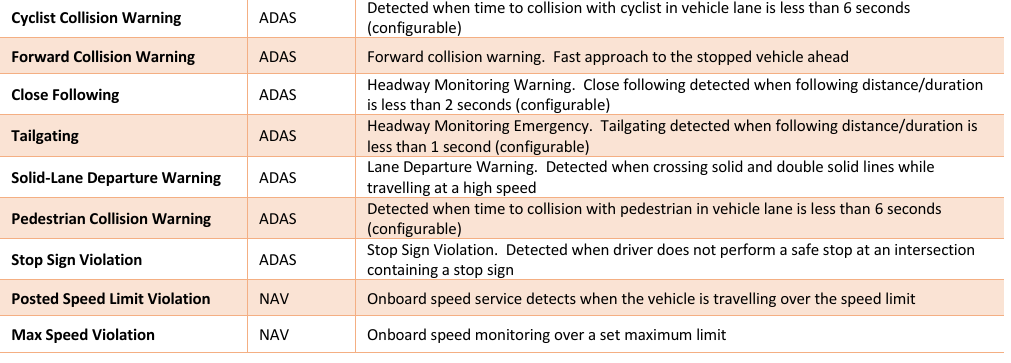

In [45]:
vf=pd.read_excel(r'C:\Users\Jose.Hurtado\DOcuments\Zonar_projects\data\bus_service\8B51423J.xlsx')
vf.info()

<class 'pandas.DataFrame'>
RangeIndex: 9759 entries, 0 to 9758
Columns: 308 entries, Message to Unnamed: 307
dtypes: float64(19), object(18), str(271)
memory usage: 22.9+ MB


In [46]:
vf['Message'].value_counts()

Message
{"notificationType":"TripInfo"             6868
{"notificationType":"CameraRunningInfo"    1387
{"notificationType":"AutoSnapshot"          955
{"notificationType":"IgnitionStatus"        404
{"notificationType":"CameraEvent"            77
{"notificationType":"ParkingHeartbeat"       68
Name: count, dtype: int64

In [47]:
vf_camera_events=vf[vf['Message'].str.contains('CameraEvent')]
vf_camera_events['Unnamed: 4'].value_counts()

Unnamed: 4
event:"SHARP_TURN"                      18
event:"USING_PHONE"                     18
event:"DROWSINESS"                      13
event:"FORWARD_COLLISION_WARNING"       10
event:"HEADWAY_MONITORING_EMERGENCY"     6
event:"HARD_BRAKE"                       5
event:"POTENTIAL_INCIDENT_MEDIUM"        3
event:"POTENTIAL_INCIDENT_LOW"           2
event:"HARD_ACCEL"                       1
event:"MANUAL"                           1
Name: count, dtype: int64

In [48]:
vf_camera_events['Unnamed: 5'].value_counts()

Unnamed: 5
eventCategory:"DMS"                   31
eventCategory:"SHARP_TURN"            18
eventCategory:"FORWARD_COLLISION"     10
eventCategory:"HEADWAY_MONITORING"     6
eventCategory:"HARD_BRAKE"             5
eventCategory:"POTENTIAL_INCIDENT"     5
eventCategory:"HARD_ACCEL"             1
eventCategory:"MANUAL"                 1
Name: count, dtype: int64

In [49]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot['Unnamed: 5']#.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\snapshot.csv')

2       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
41      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
54      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
77      url:"https://cdn.vidfleet-api.gpstrackit.com/c...
                              ...                        
9727    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9733    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9740    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9743    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
9755    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
Name: Unnamed: 5, Length: 955, dtype: str

In [50]:
vf_date_time=vf[vf['Unnamed: 3'].str.contains('time')]
vf_date_time['Unnamed: 3']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
print(vf_date_time.iloc[0,103])

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i])

nan
2026-10-01 05:44:23  ->  1790851463.0
2026-10-01 05:54:21  ->  1790852061.0
2026-10-01 06:14:20.399000  ->  1790853260.399
2026-10-01 06:24:21.200000  ->  1790853861.2
2026-10-01 06:44:21.066000  ->  1790855061.066
2026-10-01 06:54:21.200000  ->  1790855661.2
2026-10-01 07:04:21.266000  ->  1790856261.266
2026-10-01 07:14:21.266000  ->  1790856861.266
2026-10-01 07:20:31.533000  ->  1790857231.533
2026-10-01 07:23:30  ->  1790857410.0
2026-10-01 07:27:31  ->  1790857651.0
2026-10-01 15:05:42  ->  1790885142.0
2026-10-01 15:15:41.266000  ->  1790885741.266
2026-10-01 15:18:37.266000  ->  1790885917.266
2026-10-01 15:42:56  ->  1790887376.0
2026-10-01 15:52:56  ->  1790887976.0
2026-10-01 16:02:56.200000  ->  1790888576.2
2026-10-01 16:04:28.200000  ->  1790888668.2
2026-10-01 16:25:34  ->  1790889934.0
2026-10-01 16:29:58  ->  1790890198.0
2026-10-01 16:38:49  ->  1790890729.0
2026-10-01 17:08:49.266000  ->  1790892529.266
2026-10-01 17:18:49.733000  ->  1790893129.733
2026-10-01 17

In [51]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot_date=[]
aux_date_time_as=[]
epoch_date_as=[]
vf_autosnapshot['Date']='NaN'

for i in range(0,vf_autosnapshot.shape[0]):
    aux_date_time_as.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date_as.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_autosnapshot.iloc[i,104]=str(epoch_date_as[i])

#vf_autosnapshot[['Unnamed: 5','Unnamed: 3','Date']].to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\autosnap_vck379.csv')       #Edit.

NO_SEATBELT


In [52]:
vf_no_seatbelt=vf[vf['Unnamed: 4'].str.contains('NO_SEATBELT')]
#vf_no_seatbelt

vf_date_time=vf_no_seatbelt[vf_no_seatbelt['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))    
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

USING_PHONE

In [53]:
using_phone=vf[vf['Unnamed: 4'].str.contains('USING_PHONE')]
#vf_no_seatbelt

vf_date_time=using_phone[using_phone['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-02 18:00:28  ->  1790982028.0  ->  speed:15.660511
2026-10-03 06:49:20  ->  1791028160.0  ->  speed:11.756496
2026-10-03 06:51:04  ->  1791028264.0  ->  speed:54.3562
2026-10-03 07:05:01  ->  1791029101.0  ->  speed:55.584076
2026-10-03 07:34:33  ->  1791030873.0  ->  speed:4.550364
2026-10-03 13:35:37  ->  1791052537.0  ->  speed:1.913115
2026-10-05 18:12:08  ->  1791241928.0  ->  speed:1.107496
2026-10-05 18:27:08  ->  1791242828.0  ->  speed:11.756496
2026-10-06 05:50:19  ->  1791283819.0  ->  speed:51.18002
2026-10-06 16:50:40  ->  1791323440.0  ->  speed:58.354668
2026-10-06 18:20:52  ->  1791328852.0  ->  speed:12.615823
2026-10-09 17:00:41  ->  1791583241.0  ->  speed:3.570656
2026-10-10 06:12:05  ->  1791630725.0  ->  speed:27.211435
2026-10-10 06:36:28  ->  1791632188.0  ->  speed:7.526527
2026-10-10 07:26:32  ->  1791635192.0  ->  speed:6.480147
2026-10-16 18:18:49  ->  1792192729.0  ->  speed:14.164095
2026-10-17 13:04:43  ->  1792260283.0  ->  speed:13.743692
2026-1

DROWSINESS

In [54]:
drowsiness=vf[vf['Unnamed: 4'].str.contains('DROWSINESS')]
#vf_no_seatbelt

vf_date_time=drowsiness[drowsiness['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 15:55:37  ->  1790888137.0  ->  speed:14.503011
2026-10-03 07:22:55  ->  1791030175.0  ->  speed:9.298892
2026-10-03 12:50:18  ->  1791049818.0  ->  speed:8.809964
2026-10-04 14:26:48  ->  1791142008.0  ->  speed:76.78392
2026-10-04 14:31:45  ->  1791142305.0  ->  speed:25.72428
2026-10-04 14:48:46  ->  1791143326.0  ->  speed:1.653836
2026-10-05 07:18:20  ->  1791202700.0  ->  speed:13.543676
2026-10-06 16:19:04  ->  1791321544.0  ->  speed:16.63096
2026-10-12 07:18:24  ->  1791807504.0  ->  speed:16.903202
2026-10-14 07:25:26  ->  1791980726.0  ->  speed:6.706091
2026-10-17 13:07:57  ->  1792260477.0  ->  speed:1.920524
2026-10-27 12:44:40  ->  1793123080.0  ->  speed:61.138226
2026-10-27 16:08:12  ->  1793135292.0  ->  speed:9.676699


YAWN

In [55]:
yawn=vf[vf['Unnamed: 4'].str.contains('YAWN')]
#vf_no_seatbelt

vf_date_time=yawn[yawn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

SHARP_TURN

In [56]:
sharp_turn=vf[vf['Unnamed: 4'].str.contains('SHARP')]
#vf_no_seatbelt

vf_date_time=sharp_turn[sharp_turn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 05:51:40  ->  1790851900.0  ->  speed:20.342367
2026-10-01 05:58:35  ->  1790852315.0  ->  speed:30.287607
2026-10-02 18:25:21  ->  1790983521.0  ->  speed:24.590857
2026-10-04 06:52:05  ->  1791114725.0  ->  speed:28.7523
2026-10-05 05:33:38  ->  1791196418.0  ->  speed:16.72356
2026-10-07 18:42:07  ->  1791416527.0  ->  speed:18.429253
2026-10-09 06:47:46  ->  1791546466.0  ->  speed:22.388828
2026-10-12 06:31:03  ->  1791804663.0  ->  speed:48.25386
2026-10-12 15:59:22  ->  1791838762.0  ->  speed:23.183336
2026-10-14 06:00:27  ->  1791975627.0  ->  speed:25.90022
2026-10-14 17:56:17  ->  1792018577.0  ->  speed:29.630148
2026-10-17 12:26:08  ->  1792257968.0  ->  speed:46.748184
2026-10-17 13:13:30  ->  1792260810.0  ->  speed:32.34518
2026-10-20 18:39:01  ->  1792539541.0  ->  speed:22.392532
2026-10-23 18:12:00  ->  1792797120.0  ->  speed:17.11248
2026-10-26 17:56:54  ->  1793055414.0  ->  speed:15.895715
2026-10-27 12:31:00  ->  1793122260.0  ->  speed:51.072605
2026

HARD_BRAKE

In [57]:
hard_brake=vf[vf['Unnamed: 4'].str.contains('HARD')]
#vf_no_seatbelt

vf_date_time=hard_brake[hard_brake['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-03 06:25:22  ->  1791026722.0  ->  speed:20.749807
2026-10-06 17:58:17  ->  1791327497.0  ->  speed:6.348656
2026-10-15 05:56:59  ->  1792061819.0  ->  speed:3.096544
2026-10-19 05:56:51  ->  1792407411.0  ->  speed:1.911263
2026-10-24 12:08:26  ->  1792861706.0  ->  speed:2.805779
2026-10-27 12:20:51  ->  1793121651.0  ->  speed:15.719776


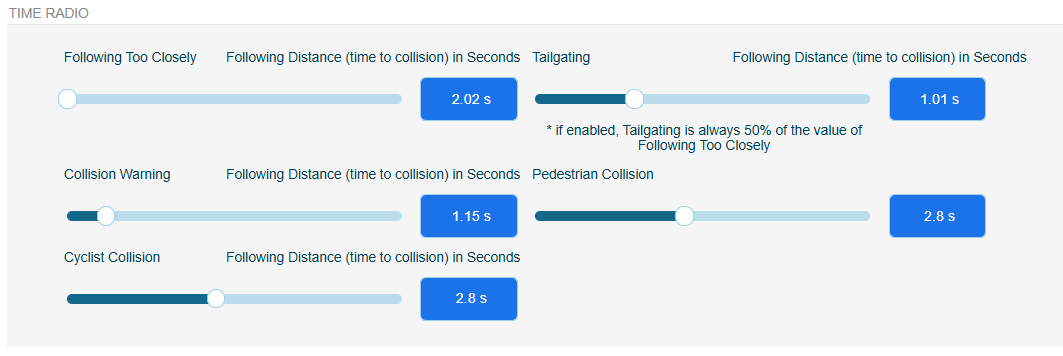

STOP_SIGN_VIOLATION

In [58]:
ssv=vf[vf['Unnamed: 4'].str.contains('STOP_SIGN_VIOLATION')]
#vf_no_seatbelt

vf_date_time=ssv[ssv['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_ssv.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

POTENTIAL_INCIDENT

In [59]:
pi=vf[vf['Unnamed: 4'].str.contains('POTENTIAL_INCIDENT')]
#vf_no_seatbelt

vf_date_time=pi[pi['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]
event=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])
    event.append(vf_date_time.iloc[i,4])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_pi.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ','->',event[i],'->',speed[i])

2026-10-20 18:33:24  ->  1792539204.0  ->  -> event:"POTENTIAL_INCIDENT_MEDIUM" -> speed:18.664455
2026-10-22 17:53:50  ->  1792709630.0  ->  -> event:"POTENTIAL_INCIDENT_MEDIUM" -> speed:15.104911
2026-10-27 16:08:50  ->  1793135330.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:9.513724
2026-10-28 13:00:44  ->  1793210444.0  ->  -> event:"POTENTIAL_INCIDENT_MEDIUM" -> speed:0.081487
2026-10-28 18:43:05  ->  1793230985.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:15.912384


HEADWAY_MONITORING_EMERGENCY

In [60]:
vf_headway=vf[vf['Unnamed: 4'].str.contains('HEADWAY')]

vf_date_time=vf_headway[vf_headway['Unnamed: 10'].str.contains('time')]
#vf_date_time['Unnamed: 9']
headway_event=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    headway_event.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,10][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])
ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_hme.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],headway_event[i])

2026-10-06 06:37:12.450000  ->  1791286632.45  ->  speed:68.97774 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-07 06:01:46.050000  ->  1791370906.05  ->  speed:65.5571 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-10 06:08:00.714000  ->  1791630480.714  ->  speed:61.677155 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-12 18:04:58.856000  ->  1791846298.856  ->  speed:64.46812 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-15 06:04:28.560000  ->  1792062268.56  ->  speed:56.461926 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-16 06:36:54.720000  ->  1792150614.72  ->  speed:65.24781 event:"HEADWAY_MONITORING_EMERGENCY"


FORWARD_COLLISION_WARNING

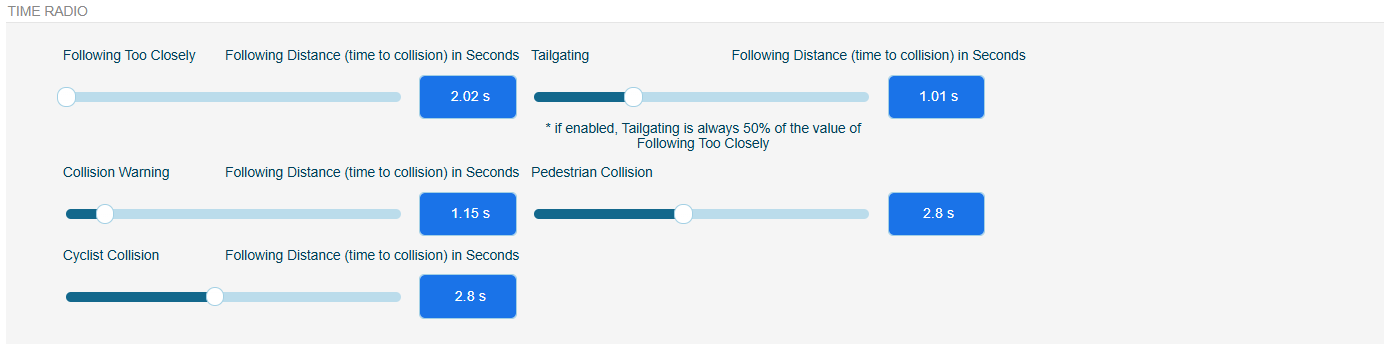
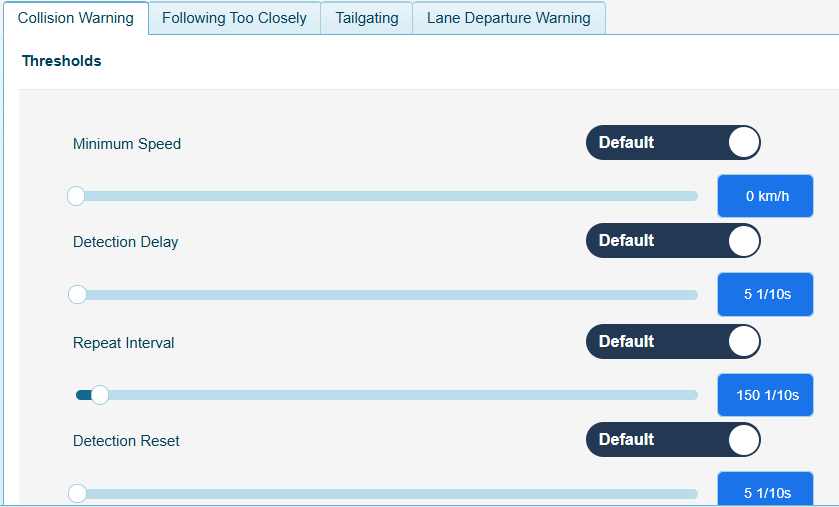

In [61]:
vf_forward=vf[vf['Unnamed: 4'].str.contains('FORWARD')]

vf_date_time=vf_forward[vf_forward['Unnamed: 10'].str.contains('time')]
#vf_date_time['Unnamed: 9']
vf_forward_event=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    vf_forward_event.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,10][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_fcw.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],vf_forward_event[i])

2026-10-01 17:05:45  ->  1790892345.0  ->  speed:23.21482 event:"FORWARD_COLLISION_WARNING"
2026-10-05 18:43:13  ->  1791243793.0  ->  speed:24.346392 event:"FORWARD_COLLISION_WARNING"
2026-10-09 18:14:20  ->  1791587660.0  ->  speed:25.940964 event:"FORWARD_COLLISION_WARNING"
2026-10-09 18:28:13  ->  1791588493.0  ->  speed:29.174557 event:"FORWARD_COLLISION_WARNING"
2026-10-14 17:36:31.514000  ->  1792017391.514  ->  speed:48.09644 event:"FORWARD_COLLISION_WARNING"
2026-10-17 12:39:30  ->  1792258770.0  ->  speed:28.035576 event:"FORWARD_COLLISION_WARNING"
2026-10-20 06:49:11  ->  1792496951.0  ->  speed:25.703909 event:"FORWARD_COLLISION_WARNING"
2026-10-23 17:16:04  ->  1792793764.0  ->  speed:10.073027 event:"FORWARD_COLLISION_WARNING"
2026-10-24 12:16:27  ->  1792862187.0  ->  speed:20.555347 event:"FORWARD_COLLISION_WARNING"
2026-10-27 17:09:14  ->  1793138954.0  ->  speed:22.144363 event:"FORWARD_COLLISION_WARNING"


In [62]:
x1=25.94*(1000/1)*(1/3600)*1.15
x2=29.17*(1000/1)*(1/3600)*1.15
print(x1,x2)

8.286388888888888 9.318194444444444


LANE_DEPARTURE

In [63]:
vf_lane_departure=vf[vf['Unnamed: 4'].str.contains('LANE_DEPARTURE')]
vf_lane_departure.head(5)

vf_date_time=vf_lane_departure[vf_lane_departure['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
vf_lane_departure=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    vf_lane_departure.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_ld.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],'->',vf_lane_departure[i])